<a href="https://colab.research.google.com/github/loulakanani/machine-learning-in-finance/blob/main/03_Credit_Risk_Analysis_and_Pipeline_Engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Credit Risk Analysis & Pipeline Engineering: Default Behavior in High-Limit Outliers

## 1. Research Question & Financial Context
How does credit default behavior differ between borrowers with low credit limits and those with extremely high credit limits (upper-tail outliers)? Furthermore, is default risk among high-limit outliers driven by **excessive credit utilization (`BILL_AMT / LIMIT_BAL`)** or by **liquidity management constraints (`PAY_AMT / BILL_AMT`)**?

---

## 2. Dataset Documentation & Schema
* **Dataset Source:** UCI Machine Learning Repository — *Default of Credit Card Clients* (`default of credit card clients.xls`).
* **License:** Creative Commons Attribution 4.0 International (CC BY 4.0).
* **Observation Unit:** One (1) individual credit card account record (`N = 30,000`).
* **Target Variable:** `default_next_month` (`1` = Default next month, `0` = No default).

### Variable Dictionary
* **`ID`:** Unique borrower identifier.
* **`LIMIT_BAL`:** Amount of given credit in New Taiwan Dollars (**NTD**).
* **`SEX`, `EDUCATION`, `MARRIAGE`, `AGE`:** Core demographic attributes.
* **`PAY_0` to `PAY_6`:** Historical monthly repayment status codes (September to April).
* **`BILL_AMT1` to `BILL_AMT6`:** Monthly bill statement amounts (**NTD**).
* **`PAY_AMT1` to `PAY_AMT6`:** Previous monthly payment amounts (**NTD**).


## 3. Data Loading & Comprehensive Integrity Audit
We load the dataset, standardize the target column name, and audit data types, missing values, cardinality, value ranges, duplicate records, and categorical class distributions.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

credit = pd.read_excel("default of credit card clients.xls", header=1)
credit = credit.rename(columns={"default payment next month": "default_next_month"})

print(f"Dataset Shape: {credit.shape[0]:,} rows x {credit.shape[1]} columns\n")

audit = pd.DataFrame({
    "dtype": credit.dtypes.astype(str),
    "missing": credit.isna().sum(),
    "unique": credit.nunique(),
    "min": credit.min(numeric_only=True),
    "max": credit.max(numeric_only=True)
})
display(audit.T)

print(f"\nDuplicate Rows: {credit.duplicated().sum()} | Unique IDs: {credit['ID'].nunique():,}")
print("\nTarget Class Balance:")
display(credit["default_next_month"].value_counts().to_frame(name="Count"))


Dataset Shape: 30,000 rows x 25 columns



,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_next_month
dtype,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,...,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64
missing,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
unique,30000,81,2,7,4,56,11,11,11,11,...,21548,21010,20604,7943,7899,7518,6937,6897,6939,2
min,1,10000,1,0,0,21,-2,-2,-2,-2,...,-170000,-81334,-339603,0,0,0,0,0,0,0
max,30000,1000000,2,6,3,79,8,8,8,8,...,891586,927171,961664,873552,1684259,896040,621000,426529,528666,1



Duplicate Rows: 0 | Unique IDs: 30,000

Target Class Balance:


,Count
default_next_month,
0,23364
1,6636


In [4]:
cat_cols_audit = ["SEX", "EDUCATION", "MARRIAGE"]
for col in cat_cols_audit:
    print(f"--- Distribution for {col} ---")
    print(credit[col].value_counts(dropna=False).to_dict())

--- Distribution for SEX ---
{2: 18112, 1: 11888}
--- Distribution for EDUCATION ---
{2: 14030, 1: 10585, 3: 4917, 5: 280, 4: 123, 6: 51, 0: 14}
--- Distribution for MARRIAGE ---
{2: 15964, 1: 13659, 3: 323, 0: 54}


**Audit Summary:** Out of 30,000 unique borrower records, **6,636 (22.12%)** defaulted in the subsequent month. All columns are complete with zero missing entries, though undocumented category codes appear in `EDUCATION` (`0, 5, 6`) and `MARRIAGE` (`0`).


## 4. Controlled Missingness & Imputation Simulation
To demonstrate leakage-safe missing data handling, we inject controlled `NaN` values into a subset of `PAY_AMT1` and apply **median imputation paired with a binary missingness indicator**.


In [5]:
demo = credit[["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]].head(8).copy()
demo.loc[[1, 4], "PAY_AMT1"] = np.nan

demo["PAY_AMT1_was_missing"] = demo["PAY_AMT1"].isna().astype(int)
median_pay = demo["PAY_AMT1"].median()
demo["PAY_AMT1"] = demo["PAY_AMT1"].fillna(median_pay)

print(f"Computed Training Median for PAY_AMT1: {median_pay:,.2f} NT$")
display(demo[["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1", "PAY_AMT1_was_missing"]])

Computed Training Median for PAY_AMT1: 1,759.00 NT$


,LIMIT_BAL,BILL_AMT1,PAY_AMT1,PAY_AMT1_was_missing
0,20000,3913,0.0,0
1,120000,2682,1759.0,1
2,90000,29239,1518.0,0
3,50000,46990,2000.0,0
4,50000,8617,1759.0,1
5,50000,64400,2500.0,0
6,500000,367965,55000.0,0
7,100000,11876,380.0,0


**Methodological Justification:** Combining median imputation with a missingness flag (`PAY_AMT1_was_missing`) ensures numerical compatibility for downstream transformers while preserving behavioral signals—since missing payment records in credit portfolios are rarely random and often correlate with repayment distress.


## 5. Duplicate Detection & Identifier Pitfalls
We simulate an exact record duplication to illustrate why primary key uniqueness alone does not guarantee economic distinctness.


In [6]:
small_subset = credit[["ID", "LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]].head(3).copy()
demo_dups = pd.concat([small_subset, small_subset.iloc[[0]]], ignore_index=True)

print(f"Simulated Dataset Shape: {demo_dups.shape}")
print(f"Exact Duplicate Rows Detected: {demo_dups.duplicated().sum()}")

Simulated Dataset Shape: (4, 4)
Exact Duplicate Rows Detected: 1


**Economic Rationale:** A unique `ID` does not automatically prove that two observations represent distinct economic events. During automated ETL ingestion or system retries, identical financial transactions can be assigned separate surrogate IDs, inflating sample weights unless deduplicated across economic attributes.


## 6. Upper- & Lower-Tail Outlier Detection (`LIMIT_BAL`)
Using the 1st and 99th percentiles as statistical thresholds, we flag extreme credit limit observations prior to evaluating whether winsorization or retention is warranted.


In [7]:
lo = credit["LIMIT_BAL"].quantile(0.01)
hi = credit["LIMIT_BAL"].quantile(0.99)

credit["LIMIT_BAL_outlier"] = (credit["LIMIT_BAL"] < lo) | (credit["LIMIT_BAL"] > hi)

print(f"1st Percentile Threshold: {lo:,.0f} NT$ | 99th Percentile Threshold: {hi:,.0f} NT$")
display(credit["LIMIT_BAL_outlier"].value_counts().to_frame(name="Record Count"))

1st Percentile Threshold: 10,000 NT$ | 99th Percentile Threshold: 500,000 NT$


,Record Count
LIMIT_BAL_outlier,
False,29794
True,206


**Outlier Assessment:** Exactly **206 records (0.69%)** exceed the 99th percentile threshold (`500,000 NT$`), while zero records fall strictly below the 1st percentile floor (`10,000 NT$`). Rather than discarding these high-limit accounts, we retain them to directly address our core research question.


## 7. Feature Partitioning & Leakage-Safe Preprocessing Pipeline
We separate numerical and categorical predictors, perform a stratified 80/20 train-test split, and construct a Scikit-Learn `ColumnTransformer` fitted exclusively on the training partition.


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

cat_cols = ["SEX", "EDUCATION", "MARRIAGE", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
num_cols = ["LIMIT_BAL", "AGE","BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6","PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"]

X = credit[num_cols + cat_cols]
y = credit["default_next_month"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=50, stratify=y)

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols)
])

X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

print(f"Transformed X_train Shape: {X_train_transformed.shape}")
print(f"Transformed X_test Shape:  {X_test_transformed.shape}")
print("\nSample Engineered Feature Names:")
print(preprocessor.get_feature_names_out()[:10])


Transformed X_train Shape: (24000, 91)
Transformed X_test Shape:  (6000, 91)

Sample Engineered Feature Names:
['num__LIMIT_BAL' 'num__AGE' 'num__BILL_AMT1' 'num__BILL_AMT2'
 'num__BILL_AMT3' 'num__BILL_AMT4' 'num__BILL_AMT5' 'num__BILL_AMT6'
 'num__PAY_AMT1' 'num__PAY_AMT2']


**Data Leakage Prevention:** Splitting the dataset prior to preprocessing and invoking `.fit_transform()` strictly on `X_train` guarantees that all imputation medians, scaling parameters ($\mu, \sigma$), and one-hot category mappings are learned solely from training observations. Applying `.transform()` to `X_test` prevents test-set distribution leakage and optimistic evaluation bias.


## 8. Research Analysis: Default Drivers in High-Limit Outliers
We segment borrowers into **Low ($\le 1\text{st}$ pct)**, **Medium**, and **Extremely High ($\ge 99\text{th}$ pct)** credit limit tiers, comparing default incidence, credit utilization (`BILL_AMT1 / LIMIT_BAL`), and liquidity repayment ratios (`PAY_AMT1 / BILL_AMT1`).


In [9]:
low_limit_threshold = credit["LIMIT_BAL"].quantile(0.01)
high_limit_threshold = credit["LIMIT_BAL"].quantile(0.99)

credit["limit_group"] = "Medium"
credit.loc[credit["LIMIT_BAL"] <= low_limit_threshold, "limit_group"] = "Low"
credit.loc[credit["LIMIT_BAL"] >= high_limit_threshold, "limit_group"] = "Extremely High"

tier_summary = credit.groupby("limit_group").agg(
    borrowers=("ID", "count"),
    default_rate=("default_next_month", "mean")
).reindex(["Low", "Medium", "Extremely High"])
tier_summary["default_rate_pct"] = (tier_summary["default_rate"] * 100).round(2)

print("Default Rates Across Credit Limit Tiers:")
display(tier_summary[["borrowers", "default_rate_pct"]])

# Utilization & Liquidity Metrics for High-Limit Outliers
credit["utilization_rate"] = credit["BILL_AMT1"] / credit["LIMIT_BAL"]
credit["payment_ratio"] = np.where(credit["BILL_AMT1"] > 0, credit["PAY_AMT1"] / credit["BILL_AMT1"], np.nan)

outliers_all = credit[credit["limit_group"] == "Extremely High"]
outliers_default = credit[(credit["limit_group"] == "Extremely High") & (credit["default_next_month"] == 1)]

metrics_comparison = pd.DataFrame({
    "All High-Limit Outliers": [
        round(outliers_all["utilization_rate"].mean(), 2),
        round(outliers_all["payment_ratio"].mean(), 2)
    ],
    "Defaulted High-Limit Outliers": [
        round(outliers_default["utilization_rate"].mean(), 2),
        round(outliers_default["payment_ratio"].mean(), 2)
    ]
}, index=["Mean Utilization Rate (BILL_AMT1 / LIMIT_BAL)", "Mean Payment Ratio (PAY_AMT1 / BILL_AMT1)"])

print("\nBehavioral Metrics Comparison (High-Limit Outliers):")
display(metrics_comparison)


Default Rates Across Credit Limit Tiers:


,borrowers,default_rate_pct
limit_group,,
Low,493,39.96
Medium,28579,22.17
Extremely High,928,11.21



Behavioral Metrics Comparison (High-Limit Outliers):


,All High-Limit Outliers,Defaulted High-Limit Outliers
Mean Utilization Rate (BILL_AMT1 / LIMIT_BAL),0.2,0.27
Mean Payment Ratio (PAY_AMT1 / BILL_AMT1),1.5,1.63


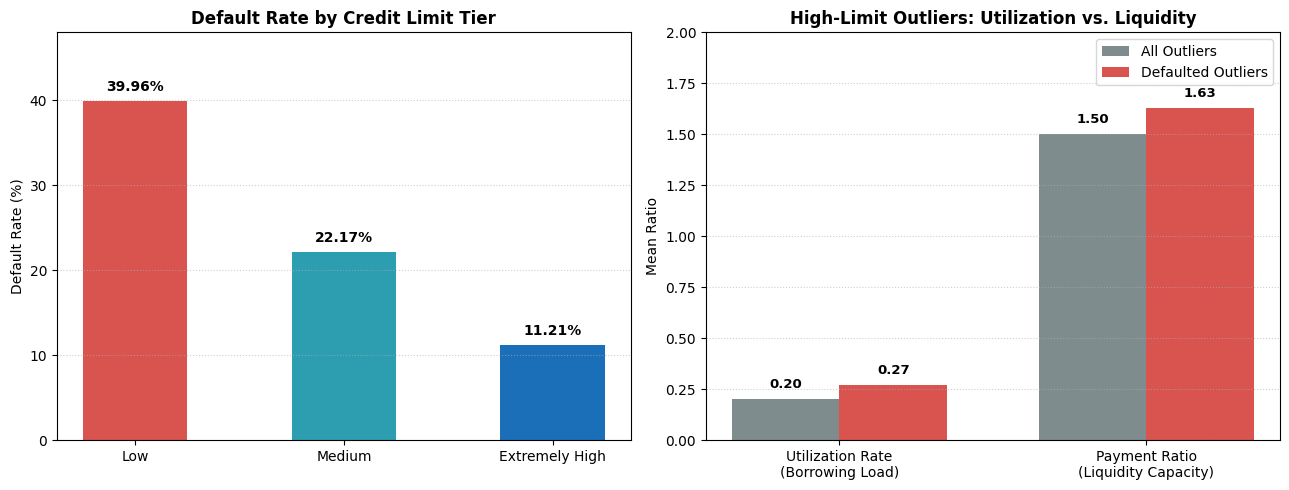

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Chart 1: Default Rate by Credit Limit Tier
colors_tier = ["#D9534F", "#2D9DB0", "#1B6FB8"]
bars1 = axes[0].bar(tier_summary.index, tier_summary["default_rate_pct"], color=colors_tier, width=0.5)
for bar in bars1:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 0.8, f"{yval:.2f}%", ha="center", va="bottom", fontweight="bold")

axes[0].set_title("Default Rate by Credit Limit Tier", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Default Rate (%)", fontsize=10)
axes[0].set_ylim(0, 48)
axes[0].grid(axis="y", linestyle=":", alpha=0.6)

# Chart 2: Utilization vs. Payment Ratio in High-Limit Outliers
x_labels = ["Utilization Rate\n(Borrowing Load)", "Payment Ratio\n(Liquidity Capacity)"]
x_pos = np.arange(len(x_labels))
width = 0.35

rects1 = axes[1].bar(x_pos - width/2, metrics_comparison["All High-Limit Outliers"], width, label="All Outliers", color="#7F8C8D")
rects2 = axes[1].bar(x_pos + width/2, metrics_comparison["Defaulted High-Limit Outliers"], width, label="Defaulted Outliers", color="#D9534F")

for rect in list(rects1) + list(rects2):
    yval = rect.get_height()
    axes[1].text(rect.get_x() + rect.get_width()/2, yval + 0.04, f"{yval:.2f}", ha="center", va="bottom", fontweight="bold", fontsize=9.5)

axes[1].set_title("High-Limit Outliers: Utilization vs. Liquidity", fontsize=12, fontweight="bold")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(x_labels, fontsize=10)
axes[1].set_ylabel("Mean Ratio", fontsize=10)
axes[1].set_ylim(0, 2.0)
axes[1].legend()
axes[1].grid(axis="y", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


## 9. Financial Interpretation & Key Takeaways
* **Inverse Risk Gradient Across Limit Tiers:** Default risk declines sharply as credit limits increase—falling from **39.96%** in the lowest limit tier ($\le 10,000\text{ NT\$}$) to **22.17%** in the medium tier, and down to **11.21%** among upper-tail outliers ($\ge 500,000\text{ NT\$}$).
* **Absence of Over-Borrowing:** Defaulted high-limit outliers maintain a very low average credit utilization rate (**0.27** vs. **0.20** across all outliers), confirming that their defaults are not triggered by maxing out credit lines.
* **Strong Liquidity Capacity:** Counterintuitively, defaulted outliers exhibit a high mean payment-to-bill ratio (**1.63** vs. **1.50**), indicating that they actively pay down balances exceeding their current monthly statements and do not suffer from chronic cash-flow shortages.
* **Strategic or Exogenous Default Drivers:** Because neither excessive leverage nor liquidity constraints explain defaults in this affluent cohort, credit losses among high-limit borrowers likely stem from **strategic defaults, disputed charges, or sudden exogenous wealth shocks** rather than gradual financial distress.

---

## 10. AI Disclosure
*Generative AI was utilized as an interactive coding assistant to structure the notebook layout, verify `scikit-learn` pipeline syntax, design comparative visualizations, and refine the English phrasing of the financial commentary. All preprocessing steps, statistical outputs, and economic interpretations were manually executed and verified.*
